In [8]:
# STEP 2 - CONNECT TO THE DATA  (run every time you open the notebook)
import boto3, s3fs
import xarray as xr

DATA_FOLDER = "elnino"       # your team's data folder - no need to change this

PROFILE = "hack-team"            # use the key you saved in Step 1 (the hub's own AWS login can't see this data)
BUCKET  = "ocean-hackathon-2026"
fs = s3fs.S3FileSystem(profile=PROFILE)
opts = {"profile": PROFILE}

# Ask AWS which team this key belongs to, so you never have to type your team name
who = boto3.Session(profile_name=PROFILE).client("sts").get_caller_identity()["Arn"]
TEAM = who.split("/")[-1]                      # e.g. "team-sound"
TEAM_DIR = f"{BUCKET}/teams/{TEAM}"            # your team's workspace (you can save files here)
DATA_DIR = f"{BUCKET}/data/{DATA_FOLDER}"      # your raw data (read-only)
OUT_DIR  = f"{TEAM_DIR}/processed"

print("Connected as:", TEAM)
print("Raw data:    ", "s3://" + DATA_DIR)
print("Your outputs:", "s3://" + TEAM_DIR)


Connected as: team-elnino
Raw data:     s3://ocean-hackathon-2026/data/elnino
Your outputs: s3://ocean-hackathon-2026/teams/team-elnino


In [3]:
%pip install -q copernicusmarine
import copernicusmarine as cm
from pathlib import Path

cm.login()   # asks for your Copernicus Marine username/password once

LOCAL_DIR = Path("cmems_daily")          # temporary local folder on the hub
LOCAL_DIR.mkdir(exist_ok=True)
S3_DAILY  = f"{OUT_DIR}/daily"           # -> s3://ocean-hackathon-2026/teams/<TEAM>/processed/daily

for dataset_id, start, end in [
    ("cmems_obs-mob_glo_phy_my_0.125deg_P1D-m",  "2002-01-01", "2024-12-31"),
    ("cmems_obs-mob_glo_phy_nrt_0.125deg_P1D-m", "2025-01-01", "2026-10-31"),
]:
    fname = f"{dataset_id}_{start[:4]}-{end[:4]}_crop.nc"
    cm.subset(
        dataset_id=dataset_id,
        minimum_latitude=46, maximum_latitude=52,
        minimum_longitude=-134, maximum_longitude=-120,
        minimum_depth=0, maximum_depth=0,
        start_datetime=start, end_datetime=end,
        output_directory=str(LOCAL_DIR),
        output_filename=fname,
        overwrite=True,
    )

    local_path = LOCAL_DIR / fname
    s3_path = f"{S3_DAILY}/{fname}"
    fs.put(str(local_path), s3_path)     # upload to your team's processed/daily
    print("Uploaded:", "s3://" + s3_path)
    local_path.unlink()                  # free up hub disk space

print(fs.ls(S3_DAILY))

Note: you may need to restart the kernel to use updated packages.


INFO - 2026-10-18T00:34:57Z - Using existing credentials from /home/jovyan/.copernicusmarine/.copernicusmarine-credentials. Use --force-overwrite combined with credentials (specified by arguments, netrc file or environment variables) to always overwrite.
INFO - 2026-10-18T00:35:00Z - Selected dataset version: "202511"
INFO - 2026-10-18T00:35:00Z - Selected dataset part: "default"


  0%|          | [00:00<?]

INFO - 2026-10-18T00:38:42Z - Total size of the download: 517.22 MB.


Uploaded: s3://ocean-hackathon-2026/teams/team-elnino/processed/daily/cmems_obs-mob_glo_phy_my_0.125deg_P1D-m_2002-2024_crop.nc


INFO - 2026-10-18T00:38:48Z - Selected dataset version: "202511"
INFO - 2026-10-18T00:38:48Z - Selected dataset part: "default"
WARNING - 2026-10-18T00:38:48Z - Some of your subset selection [2025-01-01 00:00:00+00:00, 2026-10-31 00:00:00+00:00] for the time dimension exceed the dataset coordinates [2024-09-08 00:00:00+00:00, 2026-10-11 00:00:00+00:00]


  0%|          | [00:00<?]

INFO - 2026-10-18T00:39:48Z - Total size of the download: 39.97 MB.


Uploaded: s3://ocean-hackathon-2026/teams/team-elnino/processed/daily/cmems_obs-mob_glo_phy_nrt_0.125deg_P1D-m_2025-2026_crop.nc
['ocean-hackathon-2026/teams/team-elnino/processed/daily/cmems_obs-mob_glo_phy_my_0.125deg_P1D-m_2002-2024_crop.nc', 'ocean-hackathon-2026/teams/team-elnino/processed/daily/cmems_obs-mob_glo_phy_nrt_0.125deg_P1D-m_2025-2026_crop.nc']


In [2]:
import numpy as np

S3_DAILY = f"{OUT_DIR}/daily"
my_path  = f"{S3_DAILY}/cmems_obs-mob_glo_phy_my_0.125deg_P1D-m_2002-2024_crop.nc"
nrt_path = f"{S3_DAILY}/cmems_obs-mob_glo_phy_nrt_0.125deg_P1D-m_2025-2026_crop.nc"

ds_my  = xr.open_dataset(fs.open(my_path),  engine="h5netcdf").load()
ds_nrt = xr.open_dataset(fs.open(nrt_path), engine="h5netcdf").load()

# Keep only the variables both products have (the NRT one sometimes has extras)
common = sorted(set(ds_my.data_vars) & set(ds_nrt.data_vars))
print("Shared variables:", common)
only = (set(ds_my.data_vars) ^ set(ds_nrt.data_vars))
if only:
    print("Dropped (in only one file):", only)

# Join along time, prefer the reprocessed (my) data wherever the dates overlap
ds = xr.concat([ds_my[common], ds_nrt[common]], dim="time", join="exact")
ds = ds.sortby("time")
_, keep = np.unique(ds.time.values, return_index=True)
ds = ds.isel(time=np.sort(keep))

# Note where each part came from
ds.attrs["source_my"]  = "cmems_obs-mob_glo_phy_my_0.125deg_P1D-m"
ds.attrs["source_nrt"] = "cmems_obs-mob_glo_phy_nrt_0.125deg_P1D-m"
ds.attrs["my_nrt_switch_date"] = str(ds_nrt.time.values[0])[:10]

# Checks: one step per day, no gaps
steps = ds.time.diff("time").values.astype("timedelta64[D]")
print("Time range:", str(ds.time.values[0])[:10], "to", str(ds.time.values[-1])[:10])
print("Days:", ds.sizes["time"], "| unique step sizes:", np.unique(steps))

# Save locally, then upload to S3
fname = "cmems_obs-mob_glo_phy_P1D-m_2002-2026_combined.nc"
ds.to_netcdf(fname, engine="h5netcdf")
fs.put(fname, f"{S3_DAILY}/{fname}")
print("Uploaded:", f"s3://{S3_DAILY}/{fname}")

Shared variables: ['mlotst', 'so', 'to', 'ugo', 'vgo', 'zo']
Time range: 2002-01-01 to 2026-10-11
Days: 9050 | unique step sizes: [1]
Uploaded: s3://ocean-hackathon-2026/teams/team-elnino/processed/daily/cmems_obs-mob_glo_phy_P1D-m_2002-2026_combined.nc


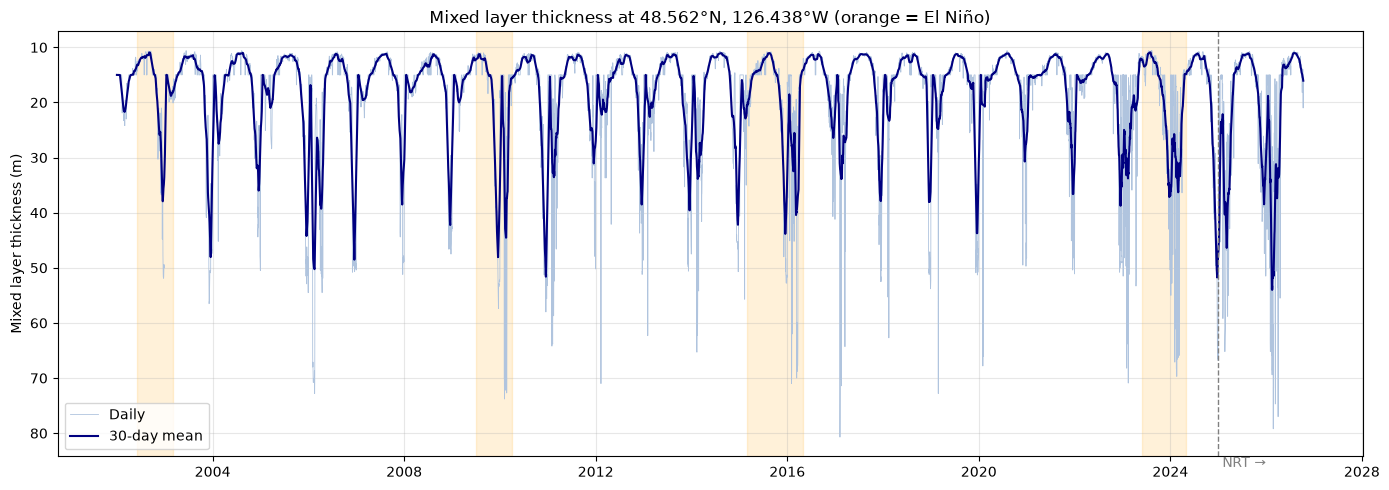

In [3]:
import matplotlib.pyplot as plt
import numpy as np

LAT, LON = 48.5, -126.5   # example: offshore of southwest Vancouver Island

pt = ds["mlotst"].sel(latitude=LAT, longitude=LON, method="nearest")
plat, plon = float(pt.latitude), float(pt.longitude)

if pt.isnull().all():
    raise ValueError(f"No data at {plat:.3f}, {plon:.3f}; it's probably land. Move the point offshore.")

smooth = pt.rolling(time=30, center=True, min_periods=15).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(pt.time, pt, color="lightsteelblue", lw=0.6, label="Daily")
ax.plot(smooth.time, smooth, color="navy", lw=1.5, label="30-day mean")

# Strong El Niño winters (shaded)
for start, end in [("2002-06", "2003-03"), ("2009-07", "2010-04"),
                   ("2015-03", "2016-05"), ("2023-06", "2024-05")]:
    ax.axvspan(np.datetime64(start), np.datetime64(end), color="orange", alpha=0.15)

# Where the reprocessed data hands over to near-real-time
switch = ds.attrs.get("my_nrt_switch_date")
if switch:
    ax.axvline(np.datetime64(switch), color="grey", ls="--", lw=1)
    ax.text(np.datetime64(switch), ax.get_ylim()[1], " NRT →", va="top", color="grey")

ax.invert_yaxis()   # deeper mixed layer plotted lower, like depth
ax.set_ylabel("Mixed layer thickness (m)")
ax.set_title(f"Mixed layer thickness at {plat:.3f}°N, {abs(plon):.3f}°W (orange = El Niño)")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

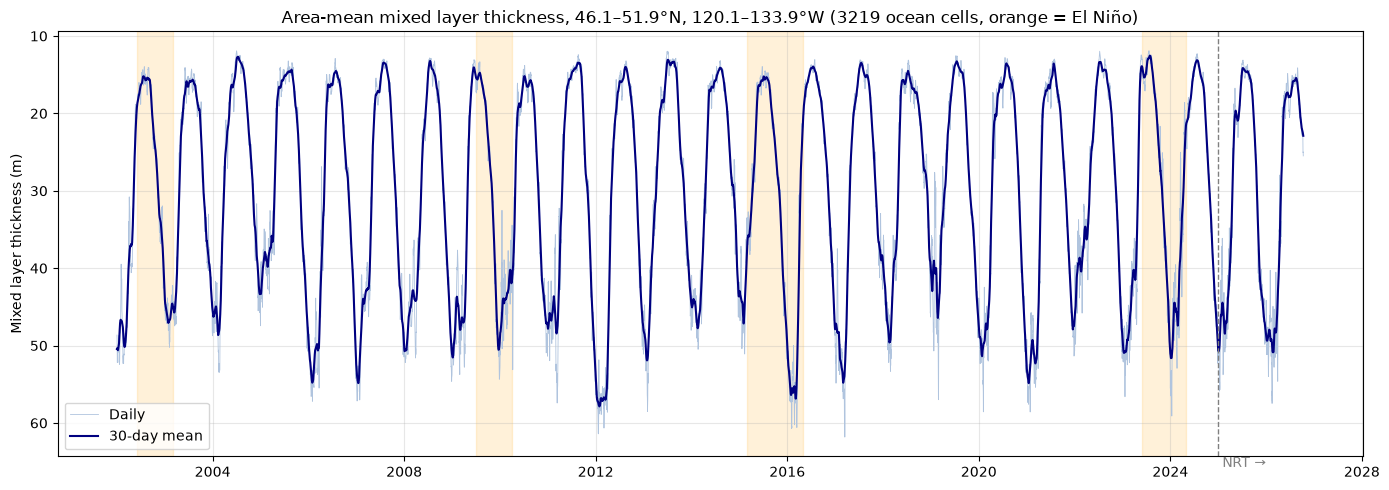

In [4]:
import matplotlib.pyplot as plt
import numpy as np

mlt = ds["mlotst"]

# Area-weighted average over all ocean points (land NaNs are skipped)
weights = np.cos(np.deg2rad(mlt.latitude))
area = mlt.weighted(weights).mean(dim=["latitude", "longitude"])

n_ocean = int(mlt.isel(time=0).notnull().sum())
lat_rng = f"{float(mlt.latitude.min()):.1f}–{float(mlt.latitude.max()):.1f}°N"
lon_rng = f"{abs(float(mlt.longitude.max())):.1f}–{abs(float(mlt.longitude.min())):.1f}°W"

smooth = area.rolling(time=30, center=True, min_periods=15).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(area.time, area, color="lightsteelblue", lw=0.6, label="Daily")
ax.plot(smooth.time, smooth, color="navy", lw=1.5, label="30-day mean")

# Strong El Niño winters (shaded)
for start, end in [("2002-06", "2003-03"), ("2009-07", "2010-04"),
                   ("2015-03", "2016-05"), ("2023-06", "2024-05")]:
    ax.axvspan(np.datetime64(start), np.datetime64(end), color="orange", alpha=0.15)

# Where the reprocessed data hands over to near-real-time
switch = ds.attrs.get("my_nrt_switch_date")
if switch:
    ax.axvline(np.datetime64(switch), color="grey", ls="--", lw=1)
    ax.text(np.datetime64(switch), ax.get_ylim()[1], " NRT →", va="top", color="grey")

ax.invert_yaxis()   # deeper mixed layer plotted lower, like depth
ax.set_ylabel("Mixed layer thickness (m)")
ax.set_title(f"Area-mean mixed layer thickness, {lat_rng}, {lon_rng} "
             f"({n_ocean} ocean cells, orange = El Niño)")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

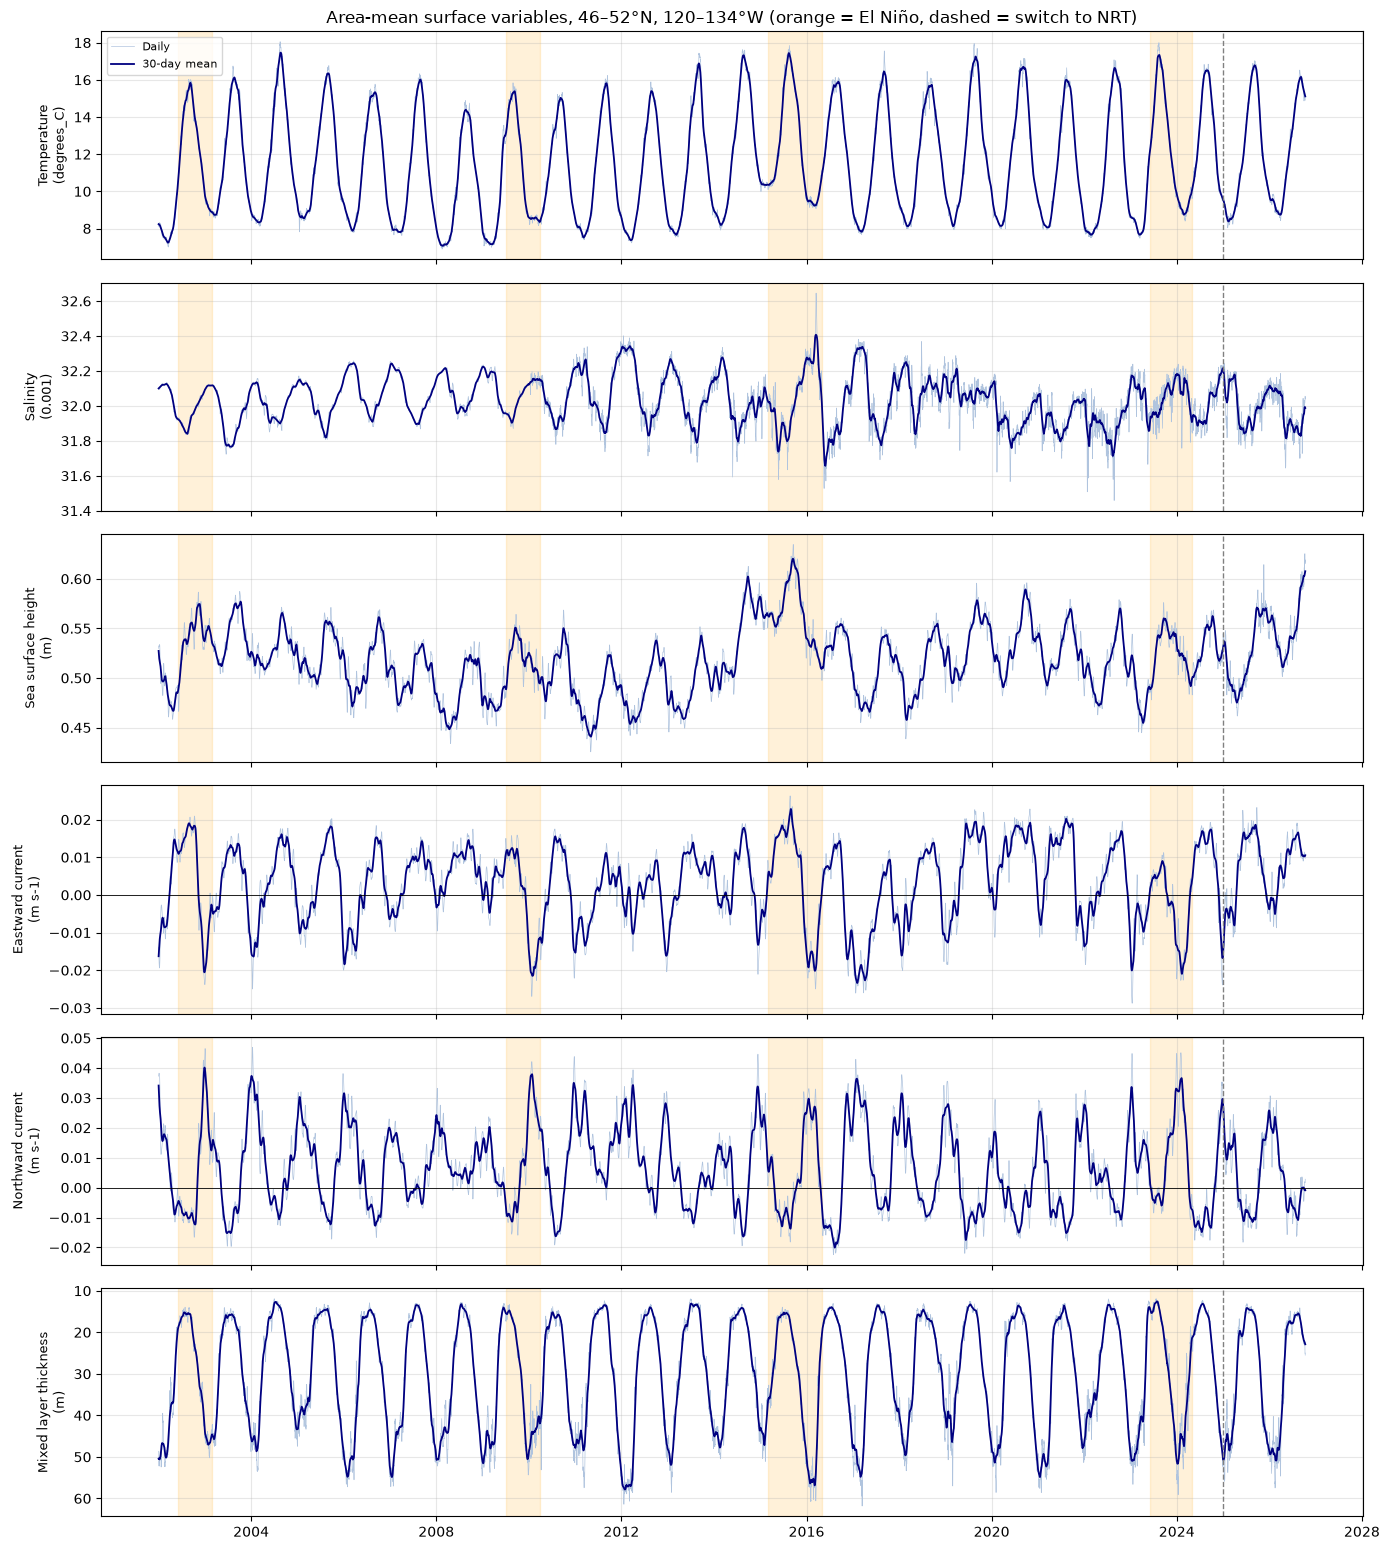

[None]

In [5]:
import matplotlib.pyplot as plt
import numpy as np

VARS = ["to", "so", "zo", "ugo", "vgo", "mlotst"]
LABELS = {
    "to": "Temperature", "so": "Salinity", "zo": "Sea surface height",
    "ugo": "Eastward current", "vgo": "Northward current", "mlotst": "Mixed layer thickness",
}
EL_NINO = [("2002-06", "2003-03"), ("2009-07", "2010-04"),
           ("2015-03", "2016-05"), ("2023-06", "2024-05")]

weights = np.cos(np.deg2rad(ds.latitude))
area = ds[VARS].weighted(weights).mean(dim=["latitude", "longitude"])
smooth = area.rolling(time=30, center=True, min_periods=15).mean()
switch = ds.attrs.get("my_nrt_switch_date")

fig, axes = plt.subplots(len(VARS), 1, figsize=(14, 2.6 * len(VARS)), sharex=True)

for ax, v in zip(axes, VARS):
    ax.plot(area.time, area[v], color="lightsteelblue", lw=0.5, label="Daily")
    ax.plot(smooth.time, smooth[v], color="navy", lw=1.3, label="30-day mean")

    for start, end in EL_NINO:
        ax.axvspan(np.datetime64(start), np.datetime64(end), color="orange", alpha=0.15)
    if switch:
        ax.axvline(np.datetime64(switch), color="grey", ls="--", lw=1)

    if v in ("ugo", "vgo"):
        ax.axhline(0, color="k", lw=0.6)
    if v == "mlotst":
        ax.invert_yaxis()   # deeper plotted lower

    units = ds[v].attrs.get("units", "")
    ax.set_ylabel(f"{LABELS[v]}\n({units})" if units else LABELS[v], fontsize=9)
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title("Area-mean surface variables, 46–52°N, 120–134°W "
                  "(orange = El Niño, dashed = switch to NRT)")
plt.tight_layout()
plt.show()

fig.savefig("all_vars_elnino.png", dpi=150)
fs.put("all_vars_elnino.png", f"{TEAM_DIR}/figures/all_vars_elnino.png")

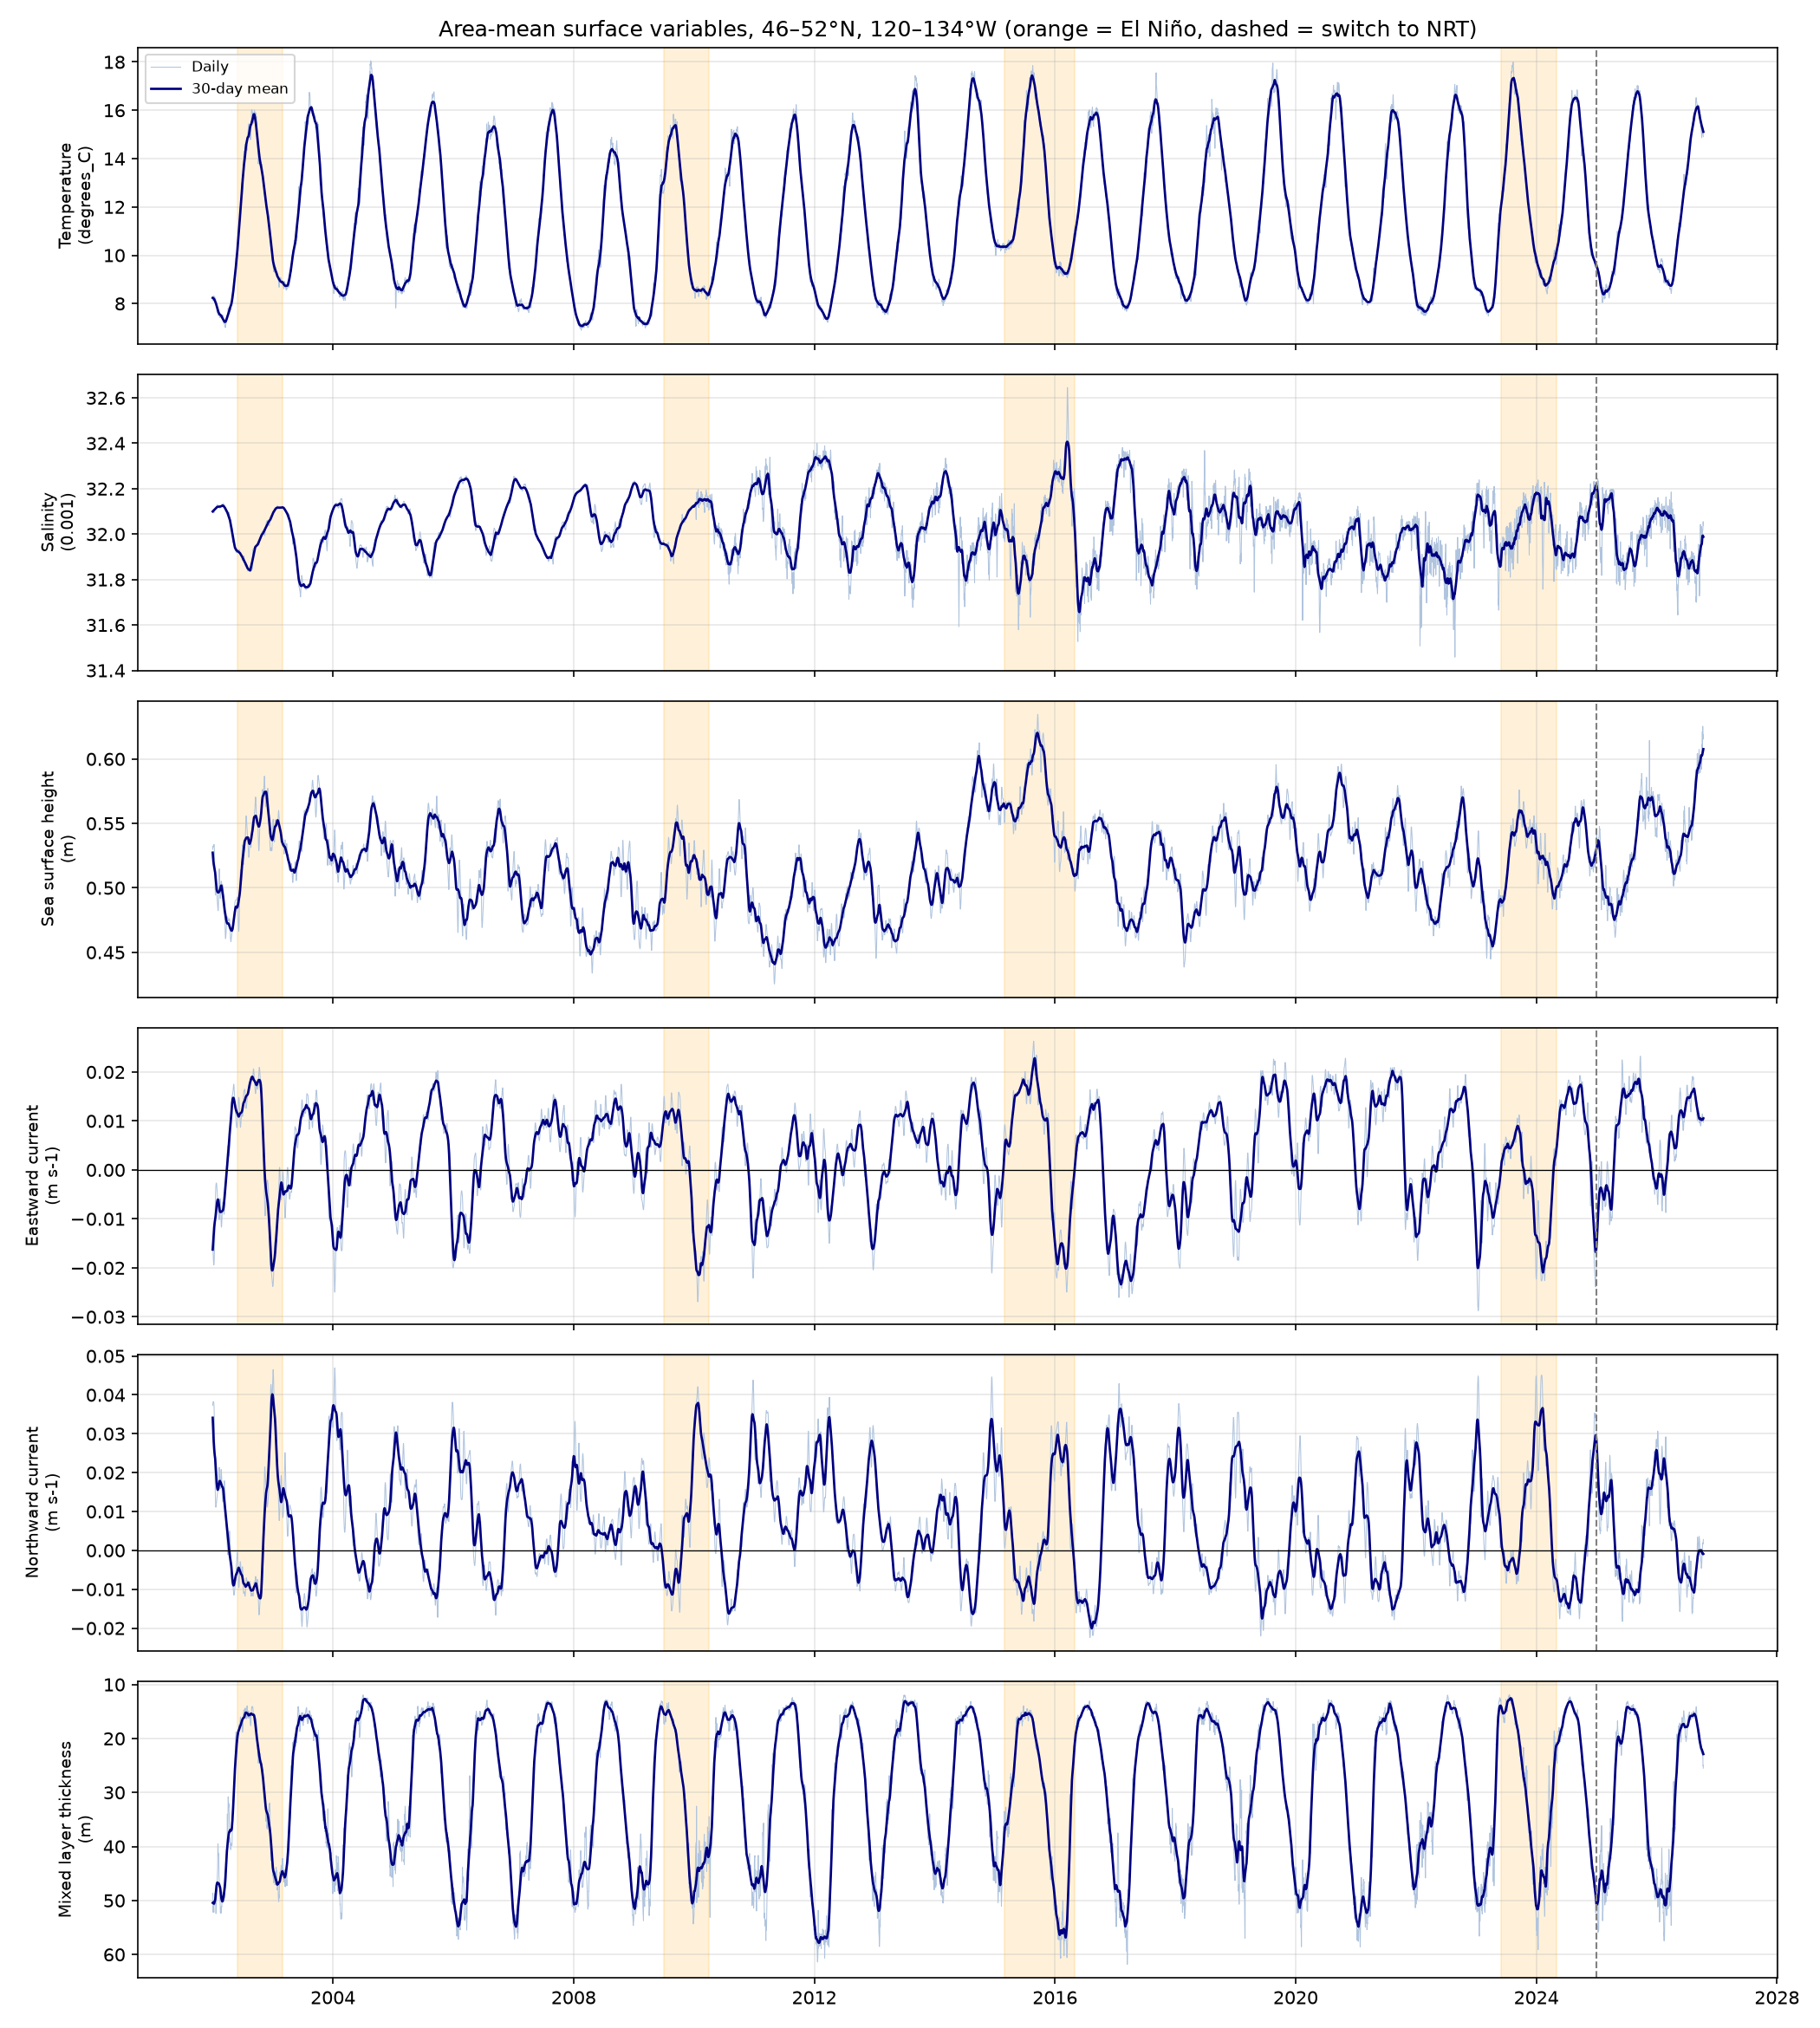

/home/jovyan/all_vars_elnino.png

In [6]:
from IPython.display import Image, FileLink, display

fname = "all_vars_elnino.png"

# If the local copy is gone (e.g. after a kernel restart), pull it back from S3
import os
if not os.path.exists(fname):
    fs.get(f"{TEAM_DIR}/figures/{fname}", fname)

display(Image(fname))   # shows the figure
display(FileLink(fname))   # click this link to download

Note: you may need to restart the kernel to use updated packages.
Train rows: 1,581,316 | Test rows: 724,517

Test set (2019 onward):
Seasonal climatology   RMSE  11.19 m   R² 0.686   (724,517 rows)
Linear regression      RMSE  11.85 m   R² 0.647   (724,517 rows)
Gradient boosting      RMSE   9.76 m   R² 0.761   (724,517 rows)

Gradient boosting, split by period (test set):
El Niño days           RMSE   8.52 m   R² 0.800   (85,653 rows)
Other days             RMSE   9.91 m   R² 0.756   (638,864 rows)


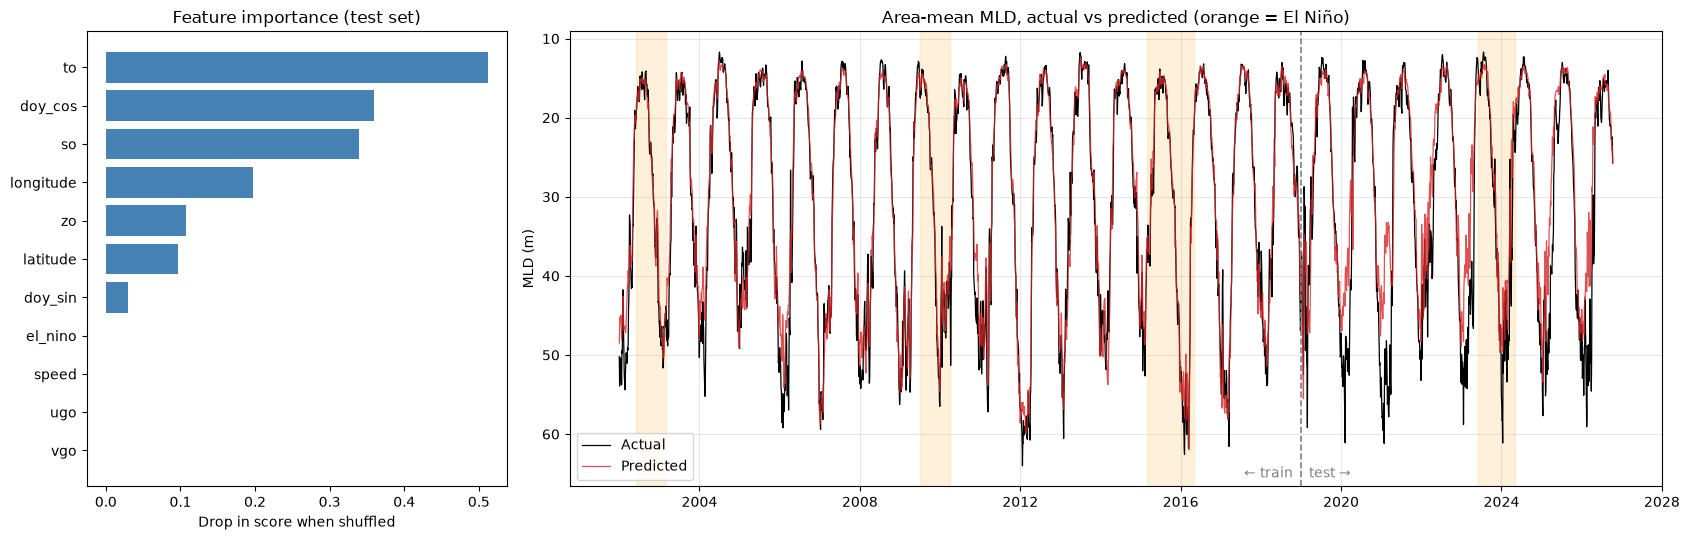

In [7]:
%pip install -q scikit-learn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score

EL_NINO = [("2002-06", "2003-03"), ("2009-07", "2010-04"),
           ("2015-03", "2016-05"), ("2023-06", "2024-05")]
SPLIT = "2019-01-01"   # train before, test from here on

# 1) Build a table: one row per (day, grid cell). Thin it out so it fits in memory.
sub = ds[["to", "so", "zo", "ugo", "vgo", "mlotst"]].isel(
    time=slice(None, None, 3), latitude=slice(None, None, 2), longitude=slice(None, None, 2))
df = sub.to_dataframe().reset_index().dropna()
if "depth" in df: df = df.drop(columns="depth")

# 2) Features: ocean fields + season + location + El Niño flag
doy = df["time"].dt.dayofyear
df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
df["speed"] = np.hypot(df["ugo"], df["vgo"])
df["el_nino"] = 0
for start, end in EL_NINO:
    df.loc[(df["time"] >= start) & (df["time"] < end), "el_nino"] = 1

FEATURES = ["to", "so", "zo", "ugo", "vgo", "speed", "doy_sin", "doy_cos",
            "latitude", "longitude", "el_nino"]

# 3) Split by time (not randomly), so neighbouring days don't leak between train and test
train = df[df["time"] < SPLIT]
test  = df[df["time"] >= SPLIT]   # includes the 2023–24 El Niño and the NRT period
print(f"Train rows: {len(train):,} | Test rows: {len(test):,}")

# MLD is skewed (a few very deep winter values), so fit on log
y_tr, y_te = np.log1p(train["mlotst"]), test["mlotst"].values

# 4) Models
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=63,
                                    early_stopping=True, validation_fraction=0.1, random_state=0)
gbm.fit(train[FEATURES], y_tr)
pred_gbm = np.expm1(gbm.predict(test[FEATURES]))

lin = LinearRegression().fit(train[FEATURES], y_tr)
pred_lin = np.expm1(lin.predict(test[FEATURES]))

# Baseline: just the average MLD for that grid cell and month (no ocean info at all)
clim = train.assign(m=train["time"].dt.month).groupby(["latitude", "longitude", "m"])["mlotst"].mean()
pred_clim = clim.reindex(pd.MultiIndex.from_arrays(
    [test["latitude"], test["longitude"], test["time"].dt.month])).values

def score(name, y, p):
    ok = ~np.isnan(p)
    rmse = mean_squared_error(y[ok], p[ok]) ** 0.5
    print(f"{name:<22} RMSE {rmse:6.2f} m   R² {r2_score(y[ok], p[ok]):.3f}   ({ok.sum():,} rows)")

print("\nTest set (2019 onward):")
score("Seasonal climatology", y_te, pred_clim)
score("Linear regression",    y_te, pred_lin)
score("Gradient boosting",    y_te, pred_gbm)

print("\nGradient boosting, split by period (test set):")
for label, mask in [("El Niño days", test["el_nino"] == 1), ("Other days", test["el_nino"] == 0)]:
    m = mask.values
    score(label, y_te[m], pred_gbm[m])

# 5) Feature importance (how much worse the model gets when each input is shuffled)
samp = test.sample(min(50_000, len(test)), random_state=0)
imp = permutation_importance(gbm, samp[FEATURES], np.log1p(samp["mlotst"]),
                             n_repeats=5, random_state=0)
order = np.argsort(imp.importances_mean)

# 6) Area-mean predicted vs actual, all years
res = df.assign(pred=np.expm1(gbm.predict(df[FEATURES]))).groupby("time")[["mlotst", "pred"]].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 2.6]})

a1.barh(np.array(FEATURES)[order], imp.importances_mean[order], color="steelblue")
a1.set_title("Feature importance (test set)")
a1.set_xlabel("Drop in score when shuffled")

a2.plot(res.index, res["mlotst"], color="black", lw=0.9, label="Actual")
a2.plot(res.index, res["pred"], color="tab:red", lw=0.9, alpha=0.8, label="Predicted")
for start, end in EL_NINO:
    a2.axvspan(np.datetime64(start), np.datetime64(end), color="orange", alpha=0.15)
a2.axvline(np.datetime64(SPLIT), color="grey", ls="--", lw=1.2)
a2.text(np.datetime64(SPLIT), 0.02, "  test →", transform=a2.get_xaxis_transform(), color="grey")
a2.text(np.datetime64(SPLIT), 0.02, "← train  ", transform=a2.get_xaxis_transform(),
        color="grey", ha="right")
a2.invert_yaxis()   # deeper plotted lower
a2.set_ylabel("MLD (m)")
a2.set_title("Area-mean MLD, actual vs predicted (orange = El Niño)")
a2.legend(loc="lower left")
a2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

fig.savefig("mld_model.png", dpi=150)